# 07 · Regresión de ventas — SportSmart Perú

¿Cuál será el volumen de ventas esperado y qué factores explican las ventas? La propuesta plantea Ventas = f(clientes, productos, precio, campañas, visitas, promociones).

**Criterio de éxito:** R² > 0,6 en ventas por producto y mes. Se entrena hasta marzo de 2026 y se prueba en abril a setiembre de 2026.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.models import regresion
from src.data.estilo_graficos import AZUL, GRIS, NARANJA, aplicar_estilo, barras_h, guardar, numero
aplicar_estilo()
res = regresion.main(); v = res['ventas']
print('Entrenamiento:', v['filas_entrenamiento'], '| Prueba:', v['filas_prueba'], '| Modelo elegido en validación:', v['mejor_modelo'])

Entrenamiento: 8667 | Prueba: 1926 | Modelo elegido en validación: XGBoost


## 1. Comparación de modelos

Los hiperparámetros y el modelo final se eligen con validación temporal, sin mirar el periodo de prueba.

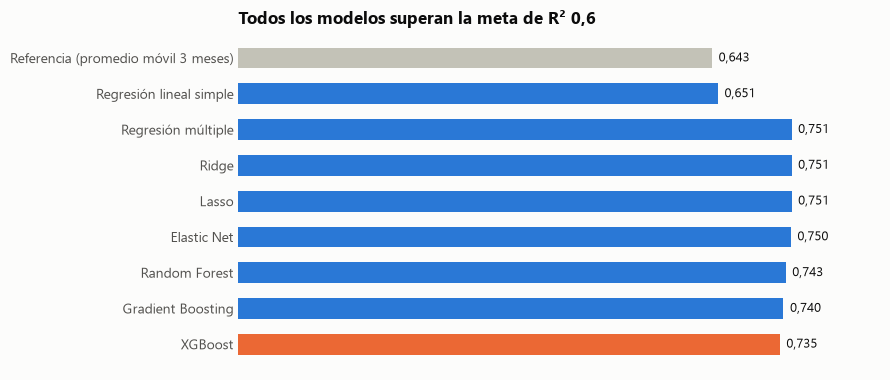

,r2,r2_validacion,rmse,mae,wape_pct,parametros
Referencia (promedio móvil 3 meses),0.643,NaN,594.4,382.7,36.7,{}
Regresión lineal simple,0.651,NaN,588.0,381.8,36.6,{}
Regresión múltiple,0.751,0.715,497.0,333.8,32.0,{}
Ridge,0.751,0.715,497.0,333.8,32.0,{'alpha': 1}
Lasso,0.751,0.715,496.4,332.8,31.9,{'alpha': 1}
Elastic Net,0.75,0.711,497.4,333.7,32.0,"{'alpha': 0.1, 'l1_ratio': 0.8}"
Random Forest,0.743,0.716,504.9,329.3,31.6,"{'max_depth': 8, 'min_samples_leaf': 10}"
Gradient Boosting,0.74,0.716,507.6,329.2,31.6,"{'learning_rate': 0.03, 'max_depth': 2}"
XGBoost,0.735,0.723,511.8,329.7,31.6,"{'learning_rate': 0.03, 'max_depth': 3}"


In [2]:
t = pd.DataFrame(v['modelos']).T; m = t.r2.astype(float)
fig, ax = plt.subplots(figsize=(9, 3.9))
col = [NARANJA if n == v['mejor_modelo'] else GRIS if n.startswith('Referencia') else AZUL for n in m.index]
barras_h(ax, list(m.index), list(m.values), col, lambda x: numero(x, 3))
ax.set_title(f"Todos los modelos superan la meta de R² {numero(v['meta_r2'], 1)}")
guardar(fig, 'regresion_modelos')
t[['r2', 'r2_validacion', 'rmse', 'mae', 'wape_pct', 'parametros']]

## 2. Resultado por mes y categoría

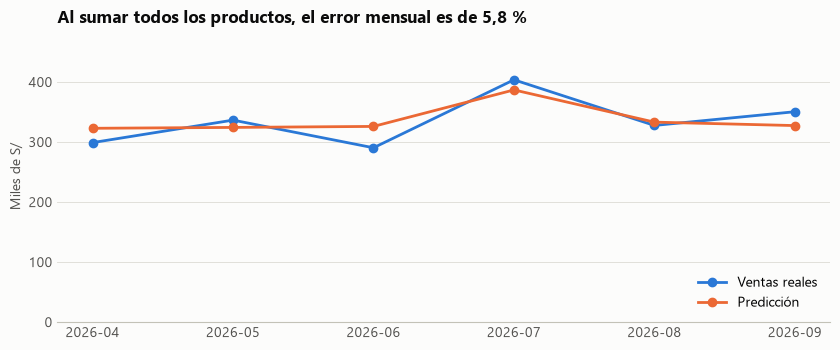

,r2,rmse,mae,wape_pct
Accesorios,0.688,291.0,210.8,27.7
Calzado,0.694,863.4,571.0,30.8
Equipamiento,0.454,337.9,242.7,40.6
Ropa inferior,0.669,400.1,319.9,28.0
Ropa superior,0.458,386.5,295.6,34.7


In [3]:
tm = pd.DataFrame({k: v['total_mensual'][k] for k in ('real', 'prediccion')}, index=v['total_mensual']['mes']) / 1000
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(tm.index, tm.real, color=AZUL, lw=2, marker='o', label='Ventas reales'); ax.plot(tm.index, tm.prediccion, color=NARANJA, lw=2, marker='o', label='Predicción')
ax.set_ylim(0, tm.values.max() * 1.2); ax.set_ylabel('Miles de S/'); ax.legend(loc='lower right')
ax.set_title(f"Al sumar todos los productos, el error mensual es de {numero(v['total_mensual']['wape_pct'])} %")
guardar(fig, 'regresion_total_mensual')
pd.DataFrame(v['por_categoria']).T

## 3. Factores que explican las ventas

Se baraja cada grupo de variables en el periodo de prueba y se mide cuánto cae el R². Un valor mayor a 1 indica que, sin ese grupo, el modelo sería peor que predecir el promedio.

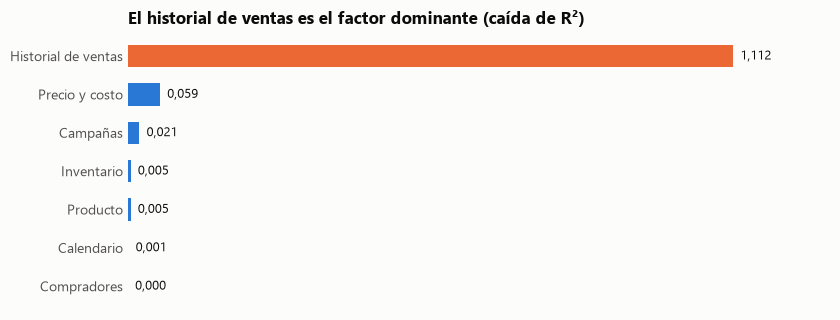

,coeficiente Ridge (S/ por desviación estándar)
ventas_media_historica,727.7
descuento_max,128.5
ventas_lag12,77.5
precio_lista,61.4
mes_del_anio,42.9
ventas_lag1,30.6
periodo,26.1
costo,-25.3


In [4]:
b = v['importancia_bloques']
fig, ax = plt.subplots(figsize=(8.5, 3.3))
barras_h(ax, list(b), list(b.values()), [NARANJA] + [AZUL] * (len(b) - 1), lambda x: numero(x, 3))
ax.set_title('El historial de ventas es el factor dominante (caída de R²)')
guardar(fig, 'regresion_factores')
pd.Series(v['coeficientes_ridge'], name='coeficiente Ridge (S/ por desviación estándar)').to_frame().head(8)

## 4. Efecto de las visitas

Las sesiones solo existen desde 2025, por lo que se compara el mismo modelo con y sin ellas en ese tramo.

In [5]:
print('Meses de entrenamiento:', res['visitas']['meses_entrenamiento'])
pd.DataFrame({k: res['visitas'][k] for k in ('sin_sesiones', 'con_sesiones')}).T

Meses de entrenamiento: 14


,r2,rmse,mae,wape_pct
sin_sesiones,0.75,497.3,335.8,32.2
con_sesiones,0.75,498.0,336.7,32.3


## 5. Análisis secundario: gasto futuro del cliente

Gasto de los 12 meses siguientes a octubre de 2025, con variables anteriores a esa fecha y validación cruzada de 5 bloques.

In [6]:
vc = res['valor_cliente']; print({k: vc[k] for k in ('compradores', 'pct_gasto_futuro_cero', 'gasto_p50', 'gasto_p99')})
pd.DataFrame(vc['modelos']).T

{'compradores': 5938, 'pct_gasto_futuro_cero': 73.4, 'gasto_p50': 0.0, 'gasto_p99': 6720.54}


,r2_medio,r2_desv,mae_medio,r2_min,r2_max
Referencia (gasto de los 12 meses previos),0.127,0.110,575.8,NaN,NaN
Ridge,0.449,0.083,460.1,0.297,0.543
Random Forest,0.490,0.085,387.2,0.327,0.560
XGBoost,0.476,0.090,394.9,0.298,0.539


## 6. Conclusiones

- **Meta cumplida:** XGBoost, elegido por tener el mejor R² de validación (0,723), logra R² de 0,735 en prueba, RMSE de S/ 511,8 y MAE de S/ 329,7. Supera al promedio móvil de 3 meses (0,643), que por sí solo ya alcanza la meta: lo relevante es la mejora sobre esa referencia.
- **Sin un ganador claro:** Ridge, Lasso y la regresión múltiple obtienen 0,751 en prueba, algo más que XGBoost. Las diferencias son pequeñas y no se cambió el modelo después de ver la prueba. Para explicar resultados, un modelo lineal casi igual de preciso es una buena alternativa.
- **Mejor en agregado que por producto:** el error total mensual es de 5,8 %, mientras que por producto y mes el WAPE es de 31,6 %. Equipamiento (R² 0,454) y Ropa superior (0,458) son las categorías más difíciles.
- **Factores:** domina el historial de ventas. Le siguen precio y costo (0,059) y campañas (0,021); inventario y producto aportan poco, y el número de compradores nada adicional.
- **Visitas:** agregar las sesiones no cambia el resultado (R² 0,750 con y sin ellas), con solo 14 meses de entrenamiento.
- **Gasto futuro del cliente:** no alcanza la meta. Random Forest logra un R² medio de 0,490, y varía entre particiones, porque 73,4 % de los compradores no gasta en esos 12 meses y unos pocos gastan mucho.

**Limitación:** el historial explica casi todo porque en la simulación cada producto mantiene un nivel de demanda parecido. Las variables de campañas son calendarios generales, no por producto.